# 01 · Lados por mapa (D18)

**Pergunta:** algum mapa favorece o ataque ou a defesa?

- Rounds regulamentares (1–24): no overtime os lados alternam a cada round e não dizem nada.
- Só mapas com histórico de lado (`has_round_sides`); o resto entra no placar e no Elo, não aqui.
- **IC por bootstrap de mapas** (cluster): rounds do mesmo mapa não são independentes.
- Teste contra 0,5 com **correção de Holm** entre os mapas.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

In [2]:
side = A.side_by_map(con)
by_map = side["by_map"]
table = by_map.assign(
    taxa_ataque=by_map.estimate.map(lambda e: e.text(percent=True)),
    p_holm=by_map.p_adj.round(4),
)[["map_name", "maps", "rounds", "taxa_ataque", "p_holm", "verdict"]]
print("Geral:", side["overall"].text(percent=True))
table

Geral: 51,1% (IC 95% 50,8%–51,5%)


,map_name,maps,rounds,taxa_ataque,p_holm,verdict
0,Abyss,406,8377,"54,1% (IC 95% 52,7%–55,5%)",0.000e+00,ataque
1,Ascent,371,7673,"47,1% (IC 95% 45,7%–48,6%)",9.000e-04,defesa
2,Bind,610,12533,"50,4% (IC 95% 49,2%–51,6%)",1.000e+00,inconclusivo
3,Breeze,665,13731,"52,2% (IC 95% 51,1%–53,3%)",1.400e-03,ataque
4,Corrode,391,8106,"51,1% (IC 95% 49,6%–52,6%)",8.185e-01,inconclusivo
5,Fracture,258,5332,"51,9% (IC 95% 50,0%–53,6%)",3.107e-01,inconclusivo
6,Haven,1081,22086,"52,5% (IC 95% 51,6%–53,5%)",0.000e+00,ataque
7,Lotus,699,14327,"52,4% (IC 95% 51,4%–53,5%)",1.000e-04,ataque
8,Pearl,670,13736,"49,5% (IC 95% 48,5%–50,7%)",1.000e+00,inconclusivo
9,Split,977,20112,"50,4% (IC 95% 49,5%–51,3%)",1.000e+00,inconclusivo


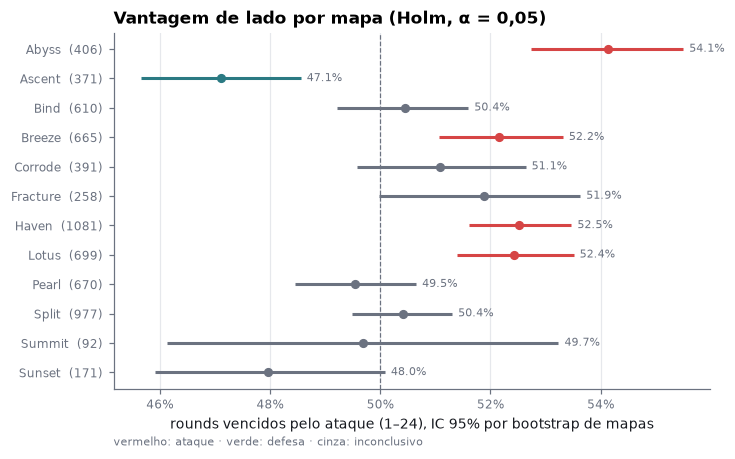

In [3]:
color = {"ataque": P.ATTACK, "defesa": P.DEFENSE, "inconclusivo": P.MUTED}
fig, ax = plt.subplots(figsize=(7, 4.2))
P.forest(ax, [f"{m}  ({n})" for m, n in zip(by_map.map_name, by_map.maps)],
         [e.value for e in by_map.estimate], [e.low for e in by_map.estimate],
         [e.high for e in by_map.estimate], null=0.5,
         colors=[color[v] for v in by_map.verdict], fmt="{:.1%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("rounds vencidos pelo ataque (1–24), IC 95% por bootstrap de mapas")
ax.set_title("Vantagem de lado por mapa (Holm, α = 0,05)")
ax.text(0, -0.16, "vermelho: ataque · verde: defesa · cinza: inconclusivo", transform=ax.transAxes,
        fontsize=7, color=P.MUTED)
P.save(fig, "lados-por-mapa.png")
plt.show()

### Por que bootstrap por mapa

Se cada round fosse independente, o IC de Wilson sobre os rounds bastaria. Não é: um time que domina
o ataque num mapa vence vários rounds seguidos. A razão entre as larguras mostra o quanto o IC
ingênuo seria estreito demais.

In [4]:
from pipeline.stats import wilson

raw = A.table(con, "mart_side_by_map")
widths = []
for name, g in raw.groupby("map_name"):
    naive = wilson(g.attack_rounds_won.sum(), g.regulation_rounds.sum())
    boot = by_map.set_index("map_name").loc[name, "estimate"]
    widths.append({"map_name": name, "wilson_rounds": naive.high - naive.low,
                   "bootstrap_mapas": boot.high - boot.low})
widths = pd.DataFrame(widths).assign(razao=lambda d: d.bootstrap_mapas / d.wilson_rounds)
widths.round(4)

,map_name,wilson_rounds,bootstrap_mapas,razao
0,Abyss,0.021,0.028,1.293
1,Ascent,0.022,0.029,1.300
2,Bind,0.018,0.024,1.359
3,Breeze,0.017,0.022,1.344
4,Corrode,0.022,0.031,1.404
5,Fracture,0.027,0.037,1.364
6,Haven,0.013,0.018,1.403
7,Lotus,0.016,0.021,1.293
8,Pearl,0.017,0.022,1.312
9,Split,0.014,0.018,1.320


## Conclusão

In [5]:
att = by_map[by_map.verdict == "ataque"]
dfn = by_map[by_map.verdict == "defesa"]
inc = by_map[by_map.verdict == "inconclusivo"]
def lst(d):
    return ", ".join(f"{r.map_name} {r.estimate.text(percent=True)}" for r in d.itertuples()) or "nenhum"
display(Markdown(f"""
- No geral, o ataque vence **{side['overall'].text(percent=True)}** dos rounds regulamentares.
- **Favorecem o ataque** (Holm, α = 0,05): {lst(att)}.
- **Favorecem a defesa:** {lst(dfn)}.
- **Inconclusivos** ({len(inc)}): {", ".join(inc.map_name)} — o IC não descarta equilíbrio.
- O IC por bootstrap de mapas é, em média, {fmt(widths.razao.mean(), 2)}× mais largo que o Wilson
  ingênuo: ignorar a correlação entre rounds produziria vereditos falsos.
"""))


- No geral, o ataque vence **51,1% (IC 95% 50,8%–51,5%)** dos rounds regulamentares.
- **Favorecem o ataque** (Holm, α = 0,05): Abyss 54,1% (IC 95% 52,7%–55,5%), Breeze 52,2% (IC 95% 51,1%–53,3%), Haven 52,5% (IC 95% 51,6%–53,5%), Lotus 52,4% (IC 95% 51,4%–53,5%).
- **Favorecem a defesa:** Ascent 47,1% (IC 95% 45,7%–48,6%).
- **Inconclusivos** (7): Bind, Corrode, Fracture, Pearl, Split, Summit, Sunset — o IC não descarta equilíbrio.
- O IC por bootstrap de mapas é, em média, 1,36× mais largo que o Wilson
  ingênuo: ignorar a correlação entre rounds produziria vereditos falsos.
